<a href="https://colab.research.google.com/github/viniciusnobcosta/pos-fiap-data-analytics/blob/main/01-analise-de-dados-e-storytelling/Analise_de_Dados_e_Storytelling_Fase1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Desafio: Análise de dados e Storytelling**

Importando as bases de dados

In [66]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [67]:
df_populacao = pd.read_excel("/content/Populacao_2013_2023.xlsx")
df_populacao.head()

,Município,uf,População 2013,População 2014,População 2015,População 2016,População 2017,População 2018,População 2019,População 2020,População 2021,População 2022,População 2023
0,ALTA FLORESTA D'OESTE,RO,25728,25652,25578,25506,25437,23167,22945,22728,22516,21494,21494
1,ARIQUEMES,RO,101269,102860,104401,105896,107345,106168,107863,109523,111148,96833,96833
2,CABIXI,RO,6495,6424,6355,6289,6224,5438,5312,5188,5067,5351,5351
3,CACOAL,RO,85863,86556,87226,87877,88507,84813,85359,85893,86416,86887,86887
4,CEREJEIRAS,RO,18041,18013,17986,17959,17934,16444,16323,16204,16088,15890,15890


In [68]:
df_infeccoes = pd.read_excel(r"/content/Base de Dados Dengue.xlsx")
df_infeccoes.head()

,municipio,uf,data_infeccoes,qtd_infeccoes
0,ALTA FLORESTA D'OESTE,RO,2013-01-01,34
1,ALTA FLORESTA D'OESTE,RO,2013-02-01,44
2,ALTA FLORESTA D'OESTE,RO,2013-03-01,15
3,ALTA FLORESTA D'OESTE,RO,2013-04-01,4
4,ALTA FLORESTA D'OESTE,RO,2013-05-01,3


Juntando as duas bases

In [69]:
# 1. Transformar o df_populacao para o formato longo (melt)
df_pop_long = df_populacao.melt(
    id_vars=['Município', 'uf'],
    var_name='ano_populacao',
    value_name='populacao'
)

# Extrair o ano como número inteiro da coluna 'ano_populacao' (ex: 'População 2013' -> 2013)
df_pop_long['ano'] = df_pop_long['ano_populacao'].str.extract(r'(\d+)').astype(int)

# Ajustar nomes de colunas de df_pop_long para facilitar o merge e remover coluna auxiliar
df_pop_long = df_pop_long.rename(columns={'Município': 'municipio'}).drop(columns=['ano_populacao'])

# Garantir que o nome das colunas de texto estejam padronizados (ex: sem espaços extras e em maiúsculas)
df_pop_long['municipio'] = df_pop_long['municipio'].str.strip().str.upper()
df_pop_long['uf'] = df_pop_long['uf'].str.strip().str.upper()

# 2. Preparar o df_infeccoes
df_infeccoes['data_infeccoes'] = pd.to_datetime(df_infeccoes['data_infeccoes'])
df_infeccoes['ano'] = df_infeccoes['data_infeccoes'].dt.year
df_infeccoes['municipio'] = df_infeccoes['municipio'].str.strip().str.upper()
df_infeccoes['uf'] = df_infeccoes['uf'].str.strip().str.upper()

# 3. Juntar as bases (merge) utilizando municipio, uf e ano
df_consolidado = pd.merge(
    df_infeccoes,
    df_pop_long,
    on=['municipio', 'uf', 'ano'],
    how='left'
)

df_consolidado.head()

,municipio,uf,data_infeccoes,qtd_infeccoes,ano,populacao
0,ALTA FLORESTA D'OESTE,RO,2013-01-01,34,2013,25728
1,ALTA FLORESTA D'OESTE,RO,2013-02-01,44,2013,25728
2,ALTA FLORESTA D'OESTE,RO,2013-03-01,15,2013,25728
3,ALTA FLORESTA D'OESTE,RO,2013-04-01,4,2013,25728
4,ALTA FLORESTA D'OESTE,RO,2013-05-01,3,2013,25728


Verificando os tipos de dados

In [70]:
df_consolidado.shape

(728772, 6)

In [71]:
df_consolidado.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 728772 entries, 0 to 728771
Data columns (total 6 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   municipio       728772 non-null  object        
 1   uf              728772 non-null  object        
 2   data_infeccoes  728772 non-null  datetime64[ns]
 3   qtd_infeccoes   728772 non-null  int64         
 4   ano             728772 non-null  int32         
 5   populacao       728772 non-null  int64         
dtypes: datetime64[ns](1), int32(1), int64(2), object(2)
memory usage: 30.6+ MB


In [72]:
df_consolidado.duplicated().sum()

np.int64(0)

- A base possui 728.772 linhas e 6 colunas;
- Não existem linhas vazias;
- Todos os tipos de colunas já estão bem definidos;
- Não há linhas com duplicidade de valor.

Selecionando apenas os dados do RJ

In [73]:
df_consolidado_rj = df_consolidado.query("uf == 'RJ'")
df_consolidado_rj.head()

,municipio,uf,data_infeccoes,qtd_infeccoes,ano,populacao
418440,ANGRA DOS REIS,RJ,2013-01-01,28,2013,181486
418441,ANGRA DOS REIS,RJ,2013-02-01,114,2013,181486
418442,ANGRA DOS REIS,RJ,2013-03-01,141,2013,181486
418443,ANGRA DOS REIS,RJ,2013-04-01,65,2013,181486
418444,ANGRA DOS REIS,RJ,2013-05-01,39,2013,181486


In [74]:
df_consolidado_rj.shape

(12144, 6)

In [75]:
df_consolidado_rj.municipio.unique()

array(['ANGRA DOS REIS', 'APERIBE', 'ARARUAMA', 'AREAL',
       'ARMACAO DOS BUZIOS', 'ARRAIAL DO CABO', 'BARRA DO PIRAI',
       'BARRA MANSA', 'BELFORD ROXO', 'BOM JARDIM',
       'BOM JESUS DO ITABAPOANA', 'CABO FRIO', 'CACHOEIRAS DE MACACU',
       'CAMBUCI', 'CARAPEBUS', 'COMENDADOR LEVY GASPARIAN',
       'CAMPOS DOS GOYTACAZES', 'CANTAGALO', 'CARDOSO MOREIRA', 'CARMO',
       'CASIMIRO DE ABREU', 'CONCEICAO DE MACABU', 'CORDEIRO',
       'DUAS BARRAS', 'DUQUE DE CAXIAS', 'ENGENHEIRO PAULO DE FRONTIN',
       'GUAPIMIRIM', 'IGUABA GRANDE', 'ITABORAI', 'ITAGUAI', 'ITALVA',
       'ITAOCARA', 'ITAPERUNA', 'ITATIAIA', 'JAPERI', 'LAJE DO MURIAE',
       'MACAE', 'MACUCO', 'MAGE', 'MANGARATIBA', 'MARICA', 'MENDES',
       'MESQUITA', 'MIGUEL PEREIRA', 'MIRACEMA', 'NATIVIDADE',
       'NILOPOLIS', 'NITEROI', 'NOVA FRIBURGO', 'NOVA IGUACU',
       'PARACAMBI', 'PARAIBA DO SUL', 'PARATY', 'PATY DO ALFERES',
       'PETROPOLIS', 'PINHEIRAL', 'PIRAI', 'PORCIUNCULA', 'PORTO REAL',
       'Q

Quantidade de casos confirmados de dengue

In [76]:
print(f'Foram confirmados {df_consolidado_rj.qtd_infeccoes.sum()} casos de dengue no RJ dentro do período de 2013-2023')

Foram confirmados 109888 casos de dengue no RJ dentro do período de 2013-2023


In [77]:
df_consolidado_rj.describe()

,data_infeccoes,qtd_infeccoes,ano,populacao
count,12144,12144.000000,12144.000000,1.214400e+04
mean,2018-06-16 13:27:16.363636224,9.048748,2018.000000,1.815749e+05
min,2013-01-01 00:00:00,0.000000,2013.000000,3.974000e+03
25%,2015-09-23 12:00:00,0.000000,2015.000000,1.812000e+04
50%,2018-06-16 00:00:00,0.000000,2018.000000,3.657300e+04
75%,2021-03-08 18:00:00,1.000000,2021.000000,1.330752e+05
max,2023-12-01 00:00:00,3027.000000,2023.000000,6.775561e+06
std,NaN,75.279793,3.162408,6.897969e+05


In [78]:
df_rj_infeccoes_municipio = df_consolidado_rj.groupby('municipio')['qtd_infeccoes'].sum().reset_index().sort_values(by='qtd_infeccoes', ascending=False)
df_rj_infeccoes_municipio.head()

,municipio,qtd_infeccoes
67,RIO DE JANEIRO,34804
14,CAMPOS DOS GOYTACAZES,13835
48,NOVA FRIBURGO,6316
91,VOLTA REDONDA,5163
36,MACAE,3739


/tmp/ipykernel_25663/523277231.py:3: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




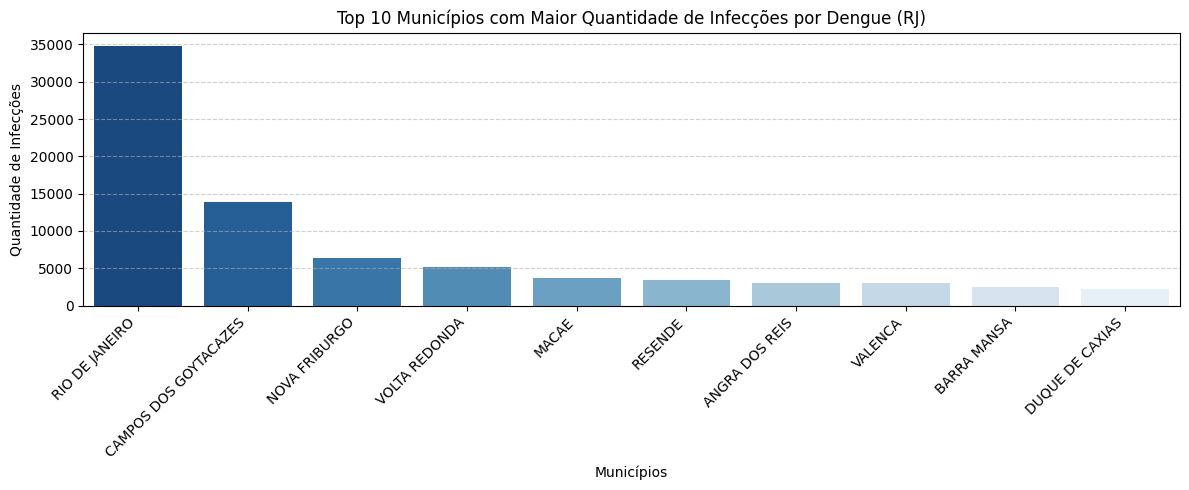

In [79]:
# Criando gráfico para visualizar a quantidade de infecções apenas dos 10 municípios com mais casos
plt.figure(figsize=(12, 5))
sns.barplot(data=df_rj_infeccoes_municipio.head(10), x='municipio', y='qtd_infeccoes', palette='Blues_r')
plt.title('Top 10 Municípios com Maior Quantidade de Infecções por Dengue (RJ)')
plt.ylabel('Quantidade de Infecções')
plt.xlabel('Municípios')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

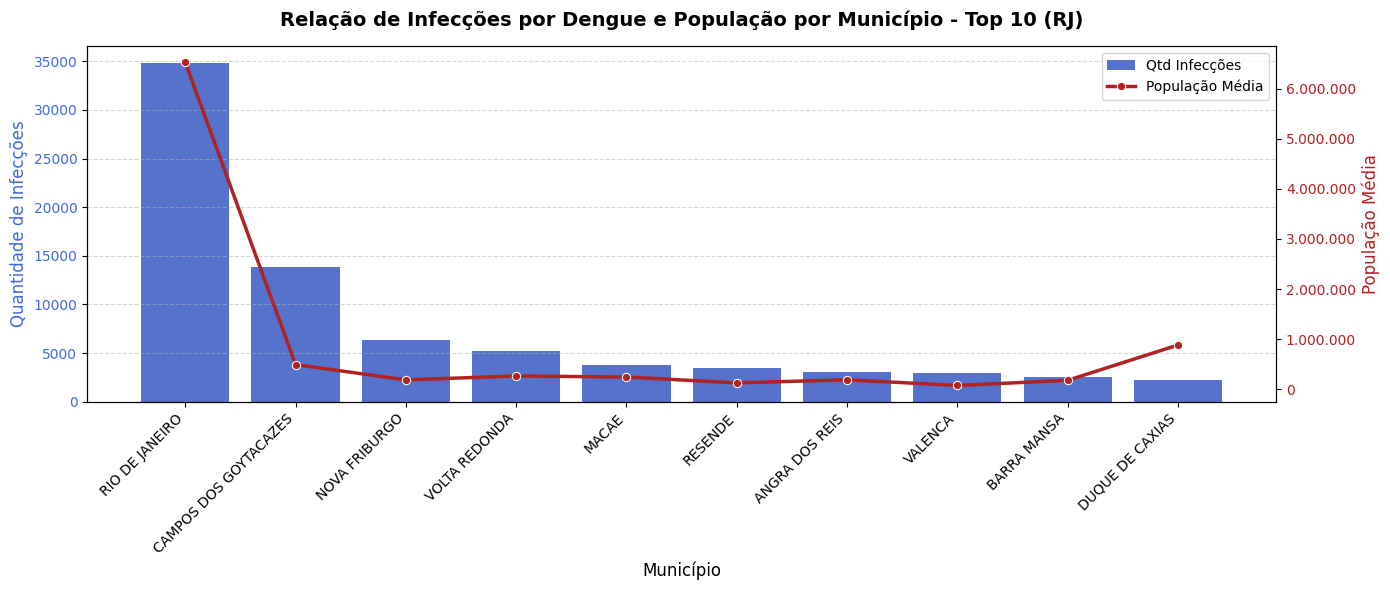

In [80]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker

# Agrupar dados por município (soma das infecções e média da população do período)
df_rj_grafico = df_consolidado_rj.groupby('municipio').agg(
    qtd_infeccoes=('qtd_infeccoes', 'sum'),
    populacao_media=('populacao', 'mean')
).reset_index().sort_values(by='qtd_infeccoes', ascending=False)

# Para evitar poluição visual, vamos focar nos 10 municípios com mais infecções
df_top_rj = df_rj_grafico.head(10)

# Configurar a figura e o primeiro eixo (barras)
fig, ax1 = plt.subplots(figsize=(14, 6))

# Plotar a quantidade de infecções como gráfico de barras
barras = sns.barplot(
    data=df_top_rj,
    x='municipio',
    y='qtd_infeccoes',
    ax=ax1,
    color='royalblue'
)

# Configurar os rótulos do eixo primário
ax1.set_title('Relação de Infecções por Dengue e População por Município - Top 10 (RJ)', fontsize=14, fontweight='bold', pad=15)
ax1.set_xlabel('Município', fontsize=12)
ax1.set_ylabel('Quantidade de Infecções', color='royalblue', fontsize=12)
ax1.tick_params(axis='y', labelcolor='royalblue')

# Definir explicitamente os ticks e depois rotacioná-los para evitar avisos
ax1.set_xticks(range(len(df_top_rj)))
ax1.set_xticklabels(df_top_rj['municipio'], rotation=45, ha='right')
ax1.grid(axis='y', linestyle='--', alpha=0.5)

# Criar o segundo eixo compartilhando o mesmo eixo X
ax2 = ax1.twinx()

# Plotar a população média como gráfico de linha
linha = sns.lineplot(
    data=df_top_rj,
    x='municipio',
    y='populacao_media',
    ax=ax2,
    color='firebrick',
    marker='o',
    linewidth=2.5
)

# Configurar os rótulos do eixo secundário
ax2.set_ylabel('População Média', color='firebrick', fontsize=12)
ax2.tick_params(axis='y', labelcolor='firebrick')

# Desativar a notação científica automática e aplicar formatação com separador de milhar
ax2.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: format(int(x), ',').replace(',', '.')))

# Criar a legenda de forma explícita e manual para evitar elementos duplicados
# barras.containers[0] é o objeto visual que representa as barras, e linha.lines[0] representa a linha desenhada
handles = [barras.containers[0], linha.lines[0]]
labels = ['Qtd Infecções', 'População Média']
ax1.legend(handles, labels, loc='upper right')

plt.tight_layout()
plt.show()

Taxa de infecção para cada município

In [81]:
# Agrupando por município para somar as infecções e obter a população média do período
df_municipios = df_consolidado_rj.groupby('municipio').agg(
    qtd_infeccoes=('qtd_infeccoes', 'sum'),
    populacao=('populacao', 'mean')
).reset_index()

# Calculando a taxa de infecção (casos por habitante)
df_municipios['taxa_infeccao'] = df_municipios['qtd_infeccoes'] / df_municipios['populacao'] * 100

# Ordenando os municípios pela quantidade de infecções de forma decrescente
df_municipios = df_municipios.sort_values(by='taxa_infeccao', ascending=False).reset_index(drop=True)

# Exibindo as primeiras linhas do novo DataFrame
df_municipios.head(10)

,municipio,qtd_infeccoes,populacao,taxa_infeccao
0,PORCIUNCULA,987,18284.090909,5.398135
1,NATIVIDADE,717,13984.818182,5.126988
2,ITALVA,630,14725.909091,4.278174
3,PORTO REAL,754,19210.727273,3.924890
4,VALENCA,2970,76965.909091,3.858851
5,SAO JOSE DO VALE DO RIO PRETO,771,21466.909091,3.591574
6,SAO JOSE DE UBA,249,7145.818182,3.484555
7,NOVA FRIBURGO,6316,187933.272727,3.360767
8,MACUCO,163,5478.272727,2.975390
9,SAPUCAIA,453,15712.636364,2.883030


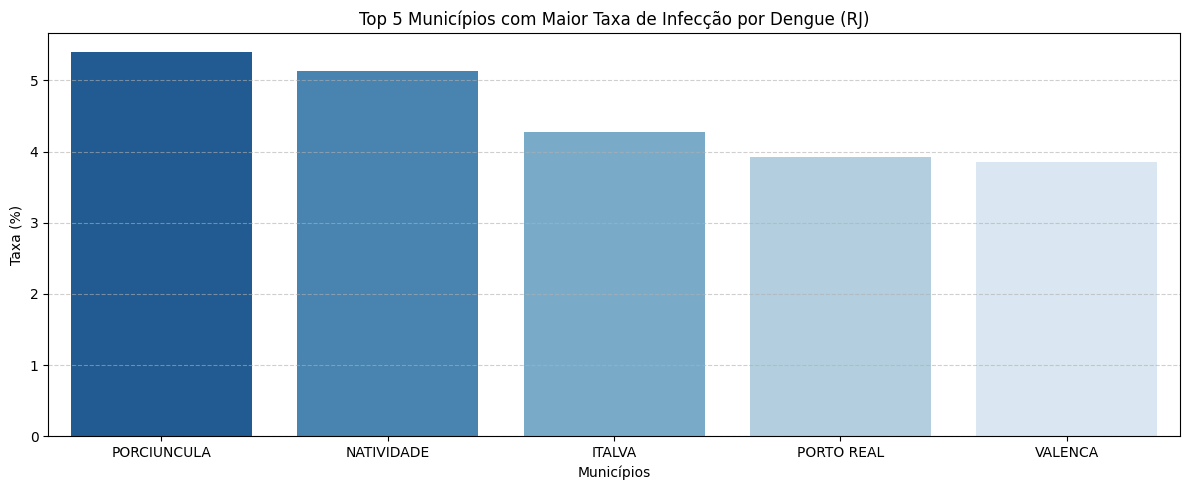

In [82]:
plt.figure(figsize=(12, 5))
sns.barplot(
    data=df_municipios.sort_values(by='taxa_infeccao', ascending=False).head(),
    x='municipio',
    y='taxa_infeccao',
    hue='municipio',
    legend=False,
    palette='Blues_r'
)
plt.title('Top 5 Municípios com Maior Taxa de Infecção por Dengue (RJ)')
plt.ylabel('Taxa (%)')
plt.xlabel('Municípios')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

1. A ilusão do Rio de Janeiro como maior problema:

Olhando apenas para as barras azuis, o município do Rio de Janeiro parece ser o caso disparadamente mais alarmante, registrando mais de 34.800 infecções (quase o triplo do segundo colocado).
No entanto, quando olhamos para a linha vermelha, vemos que o Rio de Janeiro tem uma população média colossal de mais de 6,5 milhões de habitantes.

2. Os verdadeiros pontos críticos (Surtos Proporcionais):

Cidades como Campos dos Goytacazes (13.835 casos para ~493 mil hab.) e Nova Friburgo (6.316 casos para ~187 mil hab.) têm populações drasticamente menores que a capital, mas registraram um número proporcionalmente muito maior de infecções.
Nova Friburgo, por exemplo, tem uma taxa de infecção de 3,36%, enquanto a capital tem apenas 0,53%. Isso significa que a intensidade do surto e o risco de infecção por habitante foram muito maiores em Nova Friburgo do que na própria capital.

Visualizando por ano

In [83]:
# Quantidade de casos por ano
infeccoes_ano = df_consolidado_rj.groupby('ano')['qtd_infeccoes'].sum().reset_index().sort_values(by='ano', ascending=True)
infeccoes_ano

,ano,qtd_infeccoes
0,2013,33398
1,2014,1483
2,2015,18730
3,2016,13721
4,2017,776
5,2018,1746
6,2019,3816
7,2020,1054
8,2021,1430
9,2022,5829


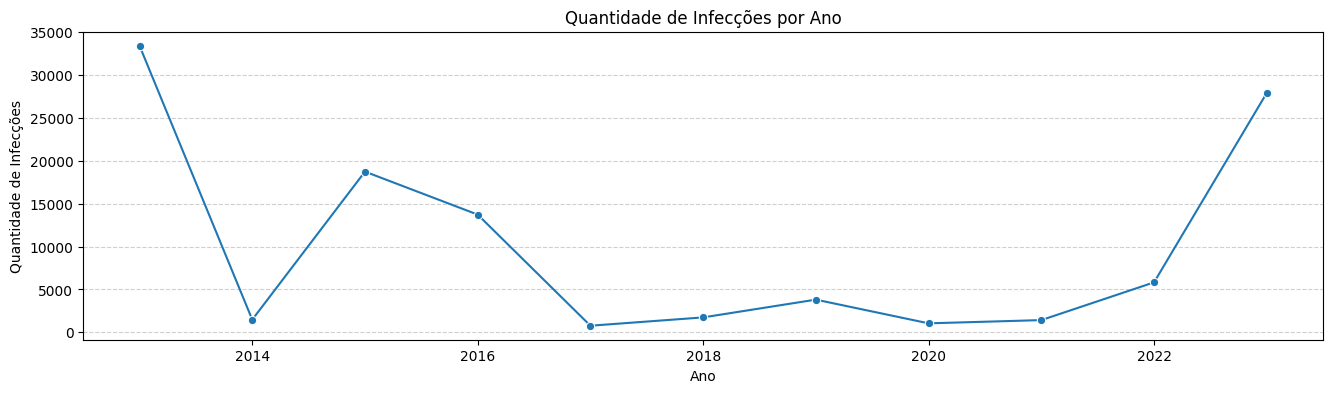

In [84]:
# criando grafico de linha para visualizar os casos por ano

plt.figure(figsize=(16, 4))
sns.lineplot(data=infeccoes_ano, x='ano', y='qtd_infeccoes', marker='o')
plt.title('Quantidade de Infecções por Ano')
plt.xlabel('Ano')
plt.ylabel('Quantidade de Infecções')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

Fica evidente que a maioria dos casos foram em 2013 e 2023, com uma queda brusca em 2014 e entre 2017-2021. Vale as perguntas:
- Porque houve uma queda tão grande entre 2013 e 2014 (de ~ 34K casos para menos de 2 mil casos)?
- Porque depois de uma queda tão grande, os casos aumentaram drasticamente em 2015?
- Porque entre 2015 e 2022, houve uma baixa dos casos no RJ e em 2023 os casos voltaram à um pico tão grande?

Vale avaliar esses pontos para saber quais possíveis causas dessa variação.

In [85]:
# criando coluna de mês
df_consolidado_rj['mes'] = df_consolidado_rj['data_infeccoes'].dt.month
df_consolidado_rj.head()

/tmp/ipykernel_25663/1702453458.py:2: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



,municipio,uf,data_infeccoes,qtd_infeccoes,ano,populacao,mes
418440,ANGRA DOS REIS,RJ,2013-01-01,28,2013,181486,1
418441,ANGRA DOS REIS,RJ,2013-02-01,114,2013,181486,2
418442,ANGRA DOS REIS,RJ,2013-03-01,141,2013,181486,3
418443,ANGRA DOS REIS,RJ,2013-04-01,65,2013,181486,4
418444,ANGRA DOS REIS,RJ,2013-05-01,39,2013,181486,5


In [86]:
# verificando os casos por ano e mês
infeccoes_mes = df_consolidado_rj.groupby(['ano', 'mes'])['qtd_infeccoes'].sum().reset_index().sort_values(by='ano', ascending=True)
infeccoes_mes

,ano,mes,qtd_infeccoes
0,2013,1,2953
1,2013,2,5001
2,2013,3,9803
3,2013,4,8648
4,2013,5,4881
...,...,...,...
127,2023,8,1372
128,2023,9,691
129,2023,10,908
130,2023,11,1855


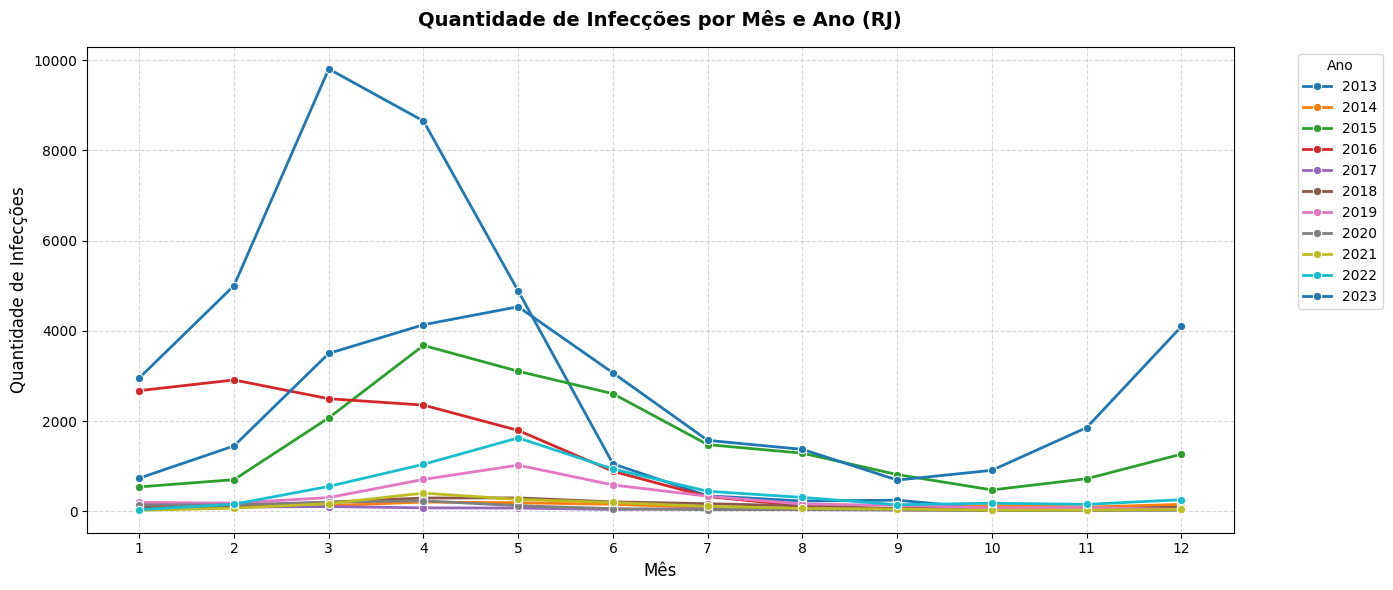

In [87]:
import matplotlib.pyplot as plt
import seaborn as sns

# Convertemos a coluna 'ano' para string para garantir mapeamento de cor categórica discreta
infeccoes_mes['ano'] = infeccoes_mes['ano'].astype(str)

# Configurar o tamanho da figura
plt.figure(figsize=(14, 6))

# Criar o gráfico de linha usando Seaborn
sns.lineplot(
    data=infeccoes_mes,
    x='mes',
    y='qtd_infeccoes',
    hue='ano',
    marker='o',
    palette='tab10',
    linewidth=2
)

# Configurações de títulos e eixos
plt.title('Quantidade de Infecções por Mês e Ano (RJ)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Mês', fontsize=12)
plt.ylabel('Quantidade de Infecções', fontsize=12)

# Forçar que o eixo X exiba todos os meses de 1 a 12
plt.xticks(ticks=range(1, 13))

# Adicionar grade para facilitar a leitura
plt.grid(True, linestyle='--', alpha=0.5)

# Posicionar a legenda fora do gráfico para não sobrepor as linhas
plt.legend(title='Ano', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

Na maioria dos anos, teve uma tendência clara de aumento nos casos entre os meses de março e maio. Ou seja, independente se os casos caíram ou aumentaram drasticamente, os meses que contém a maior parte dos casos de infecção são nos meses de março, abril e maio. Vale estudar se algo em específico aconteceu ou acontece entre esses meses.

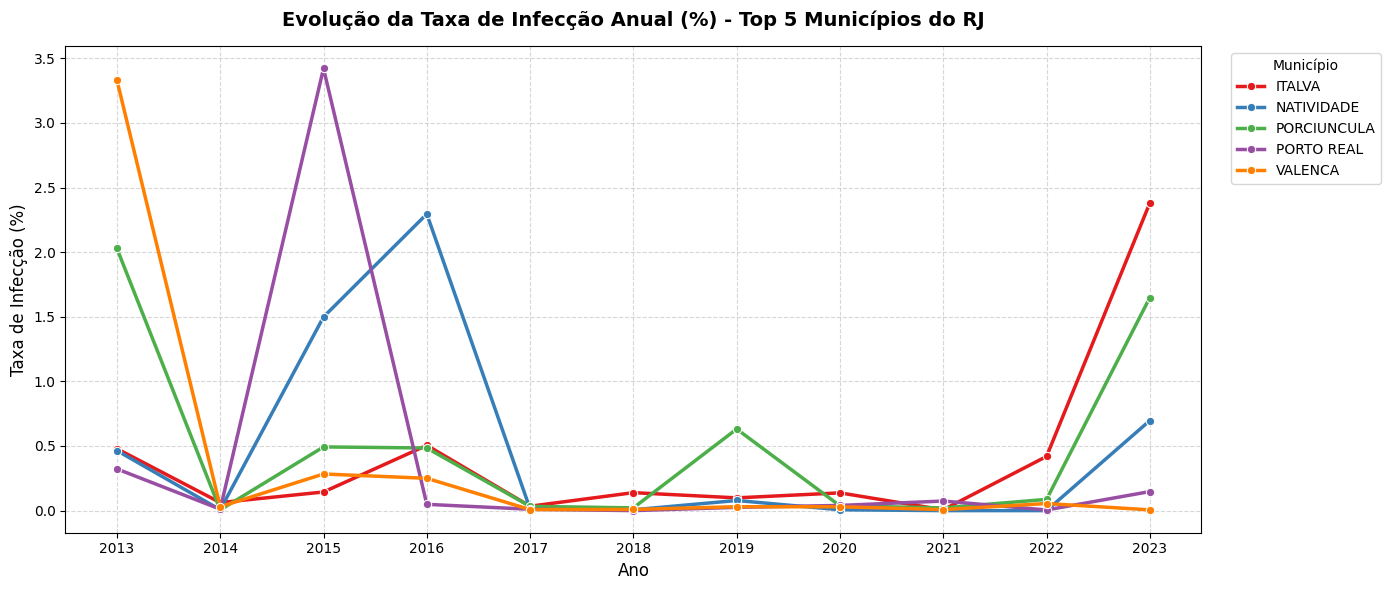

In [88]:
# 1. Agrupar os dados por município e ano para obter a soma anual de infecções e a população daquele ano
df_taxa_ano = df_consolidado_rj.groupby(['municipio', 'ano']).agg(
    qtd_infeccoes=('qtd_infeccoes', 'sum'),
    populacao=('populacao', 'first')
).reset_index()

# 2. Calcular a taxa de infecção anual (%) para cada município
df_taxa_ano['taxa_infeccao_pct'] = (df_taxa_ano['qtd_infeccoes'] / df_taxa_ano['populacao']) * 100

# 3. Identificar os 5 municípios com as maiores taxas médias de infecção para filtrar o gráfico (evita poluição visual)
top_5_municipios = df_taxa_ano.groupby('municipio')['taxa_infeccao_pct'].mean().nlargest(5).index
df_filtrado = df_taxa_ano[df_taxa_ano['municipio'].isin(top_5_municipios)].copy()

# Garantir que o ano seja tratado como número inteiro para formatação do eixo X
df_filtrado['ano'] = df_filtrado['ano'].astype(int)

# Configurar tamanho da figura
plt.figure(figsize=(14, 6))

# Criar o gráfico de linhas utilizando Seaborn
sns.lineplot(
    data=df_filtrado,
    x='ano',
    y='taxa_infeccao_pct',
    hue='municipio',
    marker='o',
    palette='Set1',
    linewidth=2.5
)

# Configurações de títulos e rótulos
plt.title('Evolução da Taxa de Infecção Anual (%) - Top 5 Municípios do RJ', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Ano', fontsize=12)
plt.ylabel('Taxa de Infecção (%)', fontsize=12)

# Garantir que o eixo X exiba todos os anos individualmente de 2013 a 2023
anos_unicos = sorted(df_filtrado['ano'].unique())
plt.xticks(ticks=anos_unicos, labels=anos_unicos)

# Adicionar grade visual
plt.grid(True, linestyle='--', alpha=0.5)

# Posicionar a legenda fora da área de desenho para evitar sobreposições
plt.legend(title='Município', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

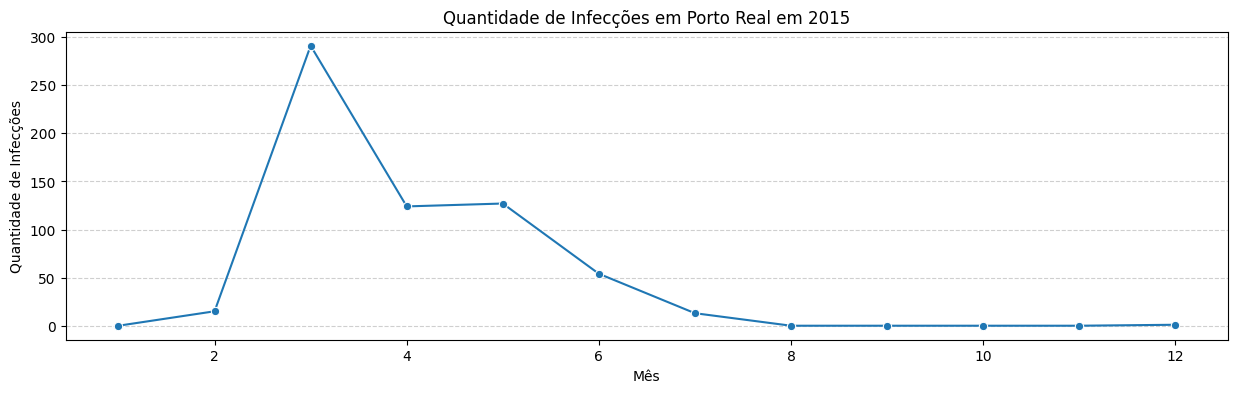

In [89]:
# Analisando a alta em Porto Real no ano de 2015
df_porto_real = df_consolidado_rj[df_consolidado_rj['municipio'] == 'PORTO REAL']
df_porto_real_2015 = df_porto_real[df_porto_real['ano'] == 2015]

# Criando gráfico para visualizar o ano de 2015
plt.figure(figsize=(15, 4))
sns.lineplot(data=df_porto_real_2015, x='mes', y='qtd_infeccoes', marker='o')
plt.title('Quantidade de Infecções em Porto Real em 2015')
plt.xlabel('Mês')
plt.ylabel('Quantidade de Infecções')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

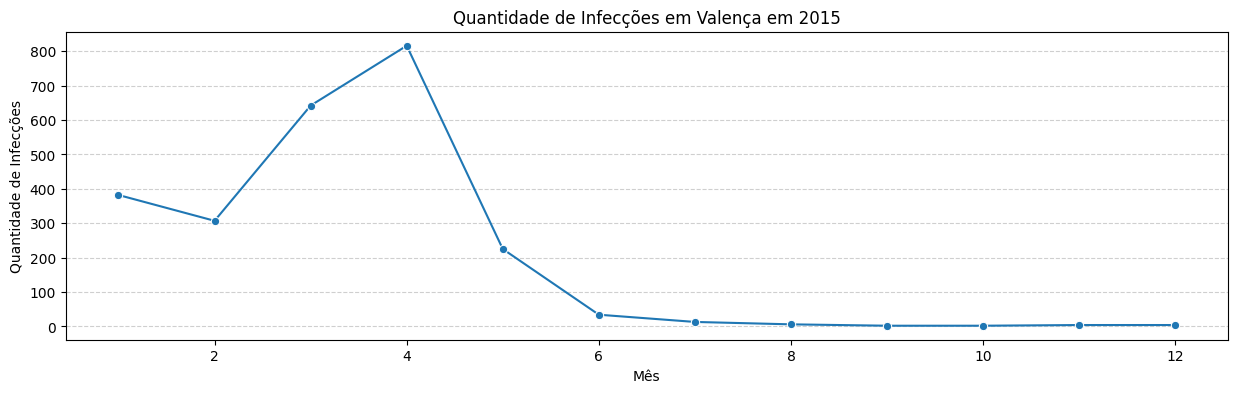

In [90]:
# Analisando a alta em Valença no ano de 2013
df_valenca = df_consolidado_rj[df_consolidado_rj['municipio'] == 'VALENCA']
df_valenca_2015 = df_valenca[df_valenca['ano'] == 2013]

# Criando gráfico para visualizar o ano de 2013
plt.figure(figsize=(15, 4))
sns.lineplot(data=df_valenca_2015, x='mes', y='qtd_infeccoes', marker='o')
plt.title('Quantidade de Infecções em Valença em 2015')
plt.xlabel('Mês')
plt.ylabel('Quantidade de Infecções')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

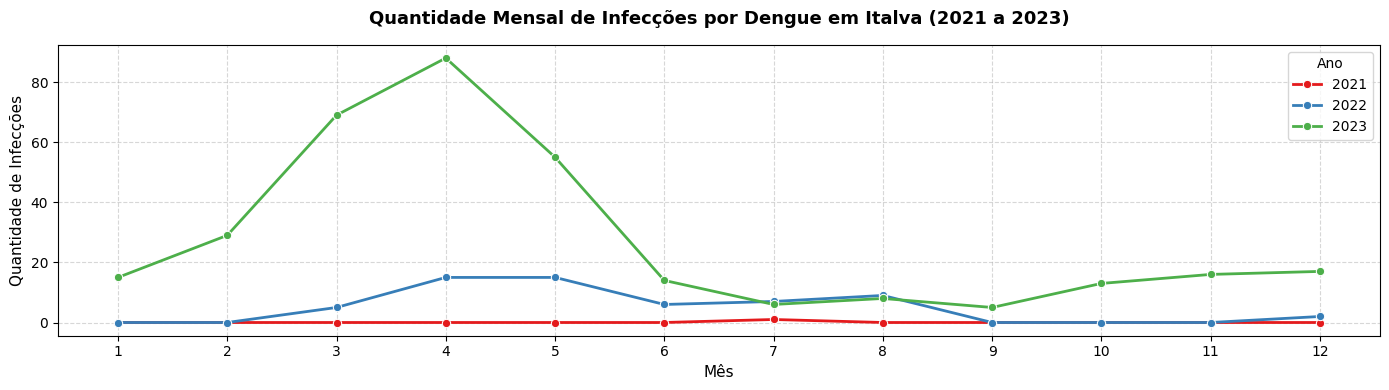

In [91]:
# Filtrando os dados de Italva entre 2021 e 2023
df_italva = df_consolidado_rj[df_consolidado_rj['municipio'] == 'ITALVA']
df_italva_2021_2023 = df_italva[(df_italva['ano'] >= 2021) & (df_italva['ano'] <= 2023)].copy()

# Convertendo a coluna de ano para string para garantir o mapeamento de cores discreto no Seaborn
df_italva_2021_2023['ano'] = df_italva_2021_2023['ano'].astype(str)

# Criando gráfico para visualizar a evolução mensal separada por ano
plt.figure(figsize=(14, 4))
sns.lineplot(data=df_italva_2021_2023,x='mes',y='qtd_infeccoes',hue='ano',marker='o',linewidth=2,palette='Set1')

plt.title('Quantidade Mensal de Infecções por Dengue em Italva (2021 a 2023)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Mês', fontsize=11)
plt.ylabel('Quantidade de Infecções', fontsize=11)
plt.xticks(ticks=range(1, 13))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Ano', loc='upper right')
plt.tight_layout()
plt.show()

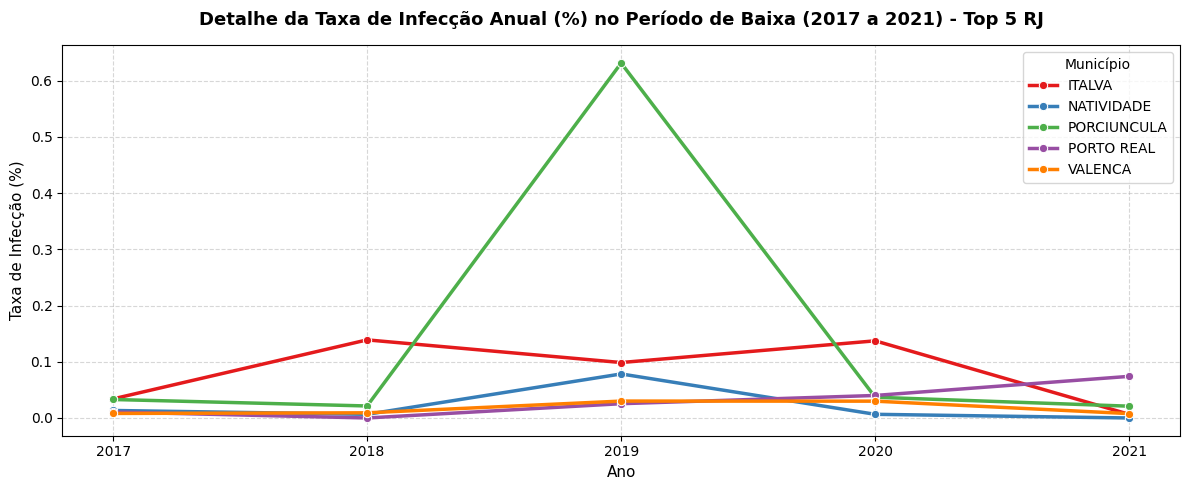

In [92]:
# 1. Definir os top 5 municípios de maior taxa de infecção histórica
top_5_nomes = ['PORCIUNCULA', 'NATIVIDADE', 'ITALVA', 'PORTO REAL', 'VALENCA']

# 2. Filtrar os dados anuais calculados anteriormente para os anos de 2017 a 2021
df_baixa_taxa = df_taxa_ano[(df_taxa_ano['municipio'].isin(top_5_nomes)) & (df_taxa_ano['ano'] >= 2017) & (df_taxa_ano['ano'] <= 2021)].copy()

# Garantir que o ano seja tratado como valor inteiro para o eixo X
df_baixa_taxa['ano'] = df_baixa_taxa['ano'].astype(int)

# 3. Criar a visualização detalhada com Matplotlib e Seaborn
plt.figure(figsize=(12, 5))
sns.lineplot(data=df_baixa_taxa, x='ano', y='taxa_infeccao_pct', hue='municipio', marker='o', linewidth=2.5, palette='Set1')

# Títulos e rótulos do gráfico
plt.title('Detalhe da Taxa de Infecção Anual (%) no Período de Baixa (2017 a 2021) - Top 5 RJ', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Ano', fontsize=11)
plt.ylabel('Taxa de Infecção (%)', fontsize=11)

# Exibir todos os anos individualmente no eixo X
plt.xticks(ticks=range(2017, 2022))

# Adicionar grade para facilitar a análise de valores próximos a zero
plt.grid(True, linestyle='--', alpha=0.5)

# Posicionar a legenda de forma organizada
plt.legend(title='Município', loc='upper right')
plt.tight_layout()
plt.show()

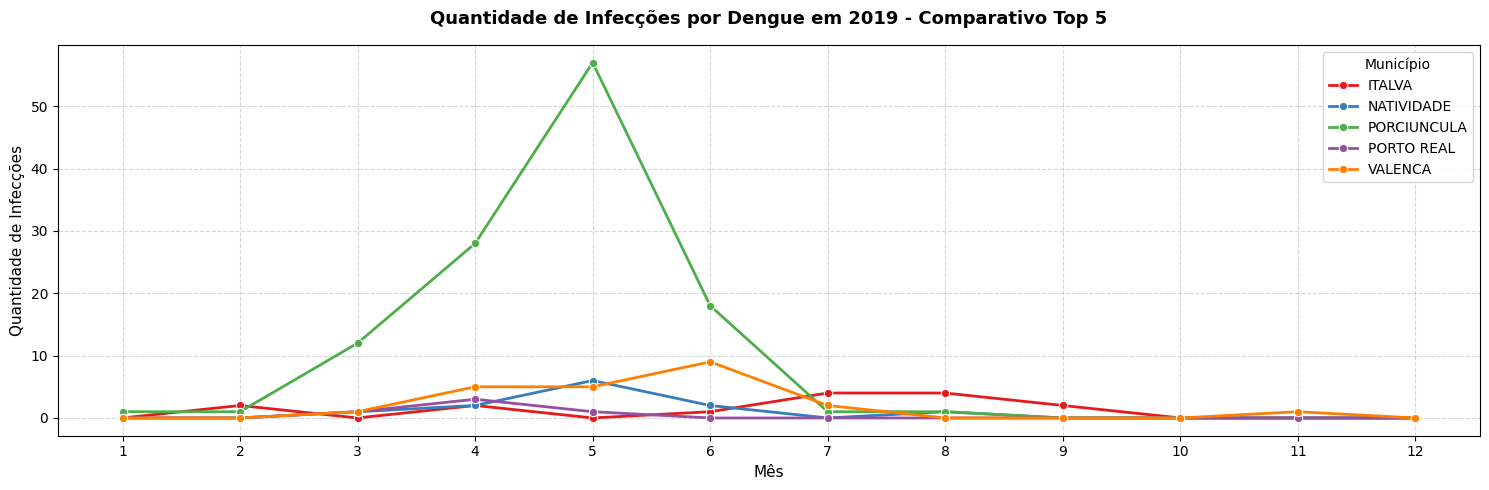

In [95]:
# Analisando Porciúncula e outros municípios do Top 5 em 2019
municipios_selecionados = ['PORCIUNCULA', 'ITALVA', 'NATIVIDADE', 'PORTO REAL', 'VALENCA']
df_selecionados_2019 = df_consolidado_rj[(df_consolidado_rj['municipio'].isin(municipios_selecionados)) & (df_consolidado_rj['ano'] == 2019)]

# Criando gráfico para visualizar o ano de 2019 comparando os municípios
plt.figure(figsize=(15, 5))
sns.lineplot(data=df_selecionados_2019, x='mes', y='qtd_infeccoes', hue='municipio', marker='o', linewidth=2,palette='Set1')

plt.title('Quantidade de Infecções por Dengue em 2019 - Comparativo Top 5', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Mês', fontsize=11)
plt.ylabel('Quantidade de Infecções', fontsize=11)
plt.xticks(ticks=range(1, 13))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Município', loc='upper right')
plt.tight_layout()
plt.show()

1. **O Surto Histórico de Porto Real (2015) e Valença (2013):**

   O gráfico mostra que o maior pico isolado da taxa anual de infecção em toda a série histórica ocorreu em Porto Real, em 2015, quando aproximadamente 3,4% da população foi infectada em um único ano. O segundo maior pico foi registrado em Valença, no início da série, em 2013, com cerca de 3,3% da população infectada. Ao analisar esses dois municípios durante seus respectivos anos de pico, observa-se que o período entre março e junho concentrou o maior número de casos. Curiosamente, esse intervalo coincide com o outono, estação que se inicia em março e termina em junho. Dessa forma, os dados sugerem que, nesse período do ano, podem existir condições mais favoráveis à transmissão do vírus, resultando em um aumento no número de infecções.

2. **A Retomada e o Pico de Italva (2023):**

   Em 2023, após alguns anos de relativa estabilidade, houve uma forte retomada das infecções. Italva registrou a maior taxa proporcional do ano, alcançando cerca de 2,4% da população infectada. Ao analisar o comportamento do município entre 2021 e 2023, observa-se que os índices permaneceram baixos e relativamente estáveis entre 2021 e 2022. No entanto, em 2023, o número de infecções aumentou de forma expressiva, repetindo um padrão já observado em outros municípios: a maior concentração de casos ocorreu durante o período do outono, entre março e junho. Esse comportamento reforça a hipótese de que essa estação do ano pode estar associada a condições mais favoráveis à transmissão do vírus.

3. **Epidemias Cíclicas e Alternadas (Dentes de Serra):**

   Os municípios não acompanham um crescimento constante ou uniforme, mas sim surtos severos e isolados em anos específicos. Por exemplo, enquanto Porto Real teve seu surto drástico em 2015, Natividade teve um pico marcante em 2016 (alcançando cerca de **2,3%**) e reduziu drasticamente nos anos seguintes.

4. **O Período de Calmaria Uniforme (2017 - 2021):**

   Praticamente todos os cinco municípios com as maiores taxas históricas mantiveram índices próximos de zero durante esse período de cinco anos. Esse comportamento pode indicar uma fase epidemiológica relativamente estável ou refletir um cenário de subnotificação, especialmente durante o auge da pandemia de COVID-19, em 2020 e 2021, quando grande parte dos recursos de saúde e da capacidade diagnóstica estava direcionada ao enfrentamento do coronavírus. Ao analisar esse período com mais detalhes, observa-se que Porciúncula apresentou, em 2019, uma taxa de infecção superior à dos anos seguintes, embora ainda considerada baixa em termos absolutos. Investigando a distribuição mensal dos casos, verificou-se que esse aumento esteve concentrado principalmente no mês de maio, enquanto os demais municípios permaneceram com níveis reduzidos de infecção ao longo do ano. Esse comportamento sugere a ocorrência de um fator específico que favoreceu a transmissão do vírus em Porciúncula naquele período. Embora os dados não permitam identificar a causa exata, o aumento expressivo dos casos em maio se destaca como um evento atípico em comparação aos demais municípios analisados.

### Verificando distribuições nos dados

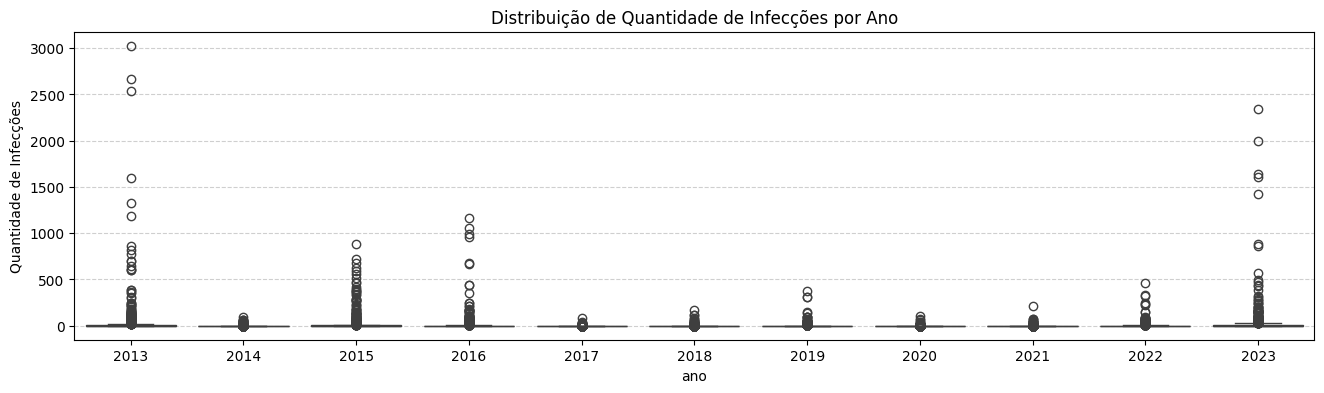

In [96]:
plt.figure(figsize=(16, 4))
sns.boxplot(data=df_consolidado_rj, x='ano', y='qtd_infeccoes')
plt.title('Distribuição de Quantidade de Infecções por Ano')
plt.ylabel('Quantidade de Infecções')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

### Análise do Boxplot: Distribuição de Quantidade de Infecções por Ano

Ao observar o comportamento das distribuições e dispersões anuais através dos diagramas de caixa (boxplot), podemos extrair conclusões epidemiológicas cruciais:

1. **Presença Massiva de Outliers (Pontos Fora da Curva):**
   - A caixa de quase todos os anos está extremamente achatada próxima ao zero, enquanto vemos diversos pontos isolados (círculos) subindo verticalmente.
   - Isso indica que a imensa maioria dos municípios do Rio de Janeiro registra pouquíssimos casos de dengue na maior parte do tempo. No entanto, em quase todos os anos, existem **municípios específicos que enfrentam surtos isolados devastadores** (representados por esses pontos altos ou *outliers*).

2. **Os Anos de Epidemia Generalizada (2013 e 2023):**
   - **2013** e **2023** não apenas têm os maiores volumes de casos acumulados, mas também apresentam os *outliers* mais extremos (com municípios registrando picos acima de 2.000 e 3.000 infecções em um único mês/período).
   - A dispersão dos pontos em 2023 mostra que o surto não foi apenas forte, mas afetou de forma muito severa múltiplos municípios simultaneamente.

3. **Assimetria Extrema dos Dados:**
   - Como a mediana (linha central da caixa) de quase todos os anos está colada na base zero, conclui-se que a distribuição de infecções de dengue por município é altamente assimétrica à direita.
   - Isso reforça que o combate à dengue precisa ser estratégico: enquanto a maior parte do estado tem uma situação sob controle, focar recursos de saúde pública de forma rápida e localizada nos municípios identificados como *outliers* é vital para conter as epidemias antes que se espalhem.

# **Relatório de Diagnóstico e Recomendações: Epidemias de Dengue no Estado do Rio de Janeiro**

Com base na análise temporal, demográfica e na distribuição espacial dos dados de infecção de dengue entre **2013 e 2023**, consolidamos os seguintes padrões, tendências e propostas de ação governamental.

---

## 1. Principais Padrões e Diagnósticos Identificados

* **A Ilusão dos Números Absolutos vs. Proporcionais:**
  * Embora a capital (**Rio de Janeiro**) lidere amplamente em números absolutos (~34.800 casos), sua imensa população dilui o impacto real sobre a comunidade, resultando em uma taxa de infecção de apenas **0,53%**.
  * Cidades de menor porte demográfico como **Porciúncula** (taxa acumulada de **5,40%**), **Natividade** (taxa de **5,13%**), **Italva** (taxa de **4,28%**), **Porto Real** (taxa de **3,92%**) e **Valença** (taxa de **3,86%**) representam os verdadeiros pontos críticos de intensidade epidemiológica no estado.

* **Sazonalidade Estrita e o Efeito Outono:**
  * Os picos históricos mostram uma forte correlação com o período de **março a junho**, que coincide exatamente com o **outono**.
  * Isso sugere que as condições climáticas e de transição de temperatura desta estação do ano criam um ambiente altamente favorável para a proliferação e transmissão do vírus pelos vetores.

* **Epidemias Cíclicas, Alternadas e Desconexas ("Dentes de Serra"):**
  * A evolução das infecções não é uniforme nem constante. Os municípios enfrentam surtos severos e isolados de forma alternada.
  * Enquanto **Valença** registrou seu pico em **2013** (com cerca de **3,3%** da população infectada) e **Porto Real** atingiu o recorde histórico em **2015** (com aproximadamente **3,4%** de infectados), **Natividade** teve seu surto drástico em **2016** (alcançando cerca de **2,3%**).

* **O Período de Calmaria (2017–2021) e a Anomalia de Porciúncula:**
  * Entre 2017 e 2021, as taxas gerais mantiveram-se muito próximas de zero. Esse comportamento indica estabilidade epidemiológica ou, possivelmente, um cenário de subnotificação decorrente do foco e dos recursos de saúde voltados ao enfrentamento da pandemia de COVID-19 (em 2020 e 2021).
  * Contudo, **2019** quebrou essa calmaria de forma localizada: **Porciúncula** apresentou uma taxa de infecção superior à dos demais municípios do grupo, com um aumento expressivo e atípico de casos concentrado especificamente no mês de **maio**.

* **A Retomada Explosiva de 2023:**
  * Após os anos de calmaria e transição, 2023 marcou o retorno severo da doença. **Italva** despontou com a maior taxa proporcional do ano, com cerca de **2,4%** de sua população infectada, concentrando a enorme maioria de seus casos também no outono (março a junho).

---

## 2. Propostas de Soluções e Ações Governamentais

### **Ação I: Antecipação Preventiva Focada na Janela do Outono**
* **Estratégia:** As ações preventivas de combate ao vetor (*Aedes aegypti*), como visitas domiciliares, eliminação de criadouros e pulverização de larvicidas, devem ser intensificadas bem antes do pico do outono, focando no período de **novembro a janeiro**.
* **Foco Temporal:** Estar com a população de mosquitos drasticamente reduzida antes de março é fundamental para impedir que a curva sazonal atinja níveis epidêmicos.

### **Ação II: Distribuição Proporcional de Recursos de Saúde**
* **Estratégia:** Alocar verbas, insumos e equipes de saúde do Estado utilizando como critério principal a **taxa de incidência proporcional (casos por habitante)** e o histórico de surtos atípicos locais, e não a população absoluta.
* **Foco Regional:** Priorizar o suporte de infraestrutura emergencial para redes de saúde de municípios de pequeno e médio porte (como os do Noroeste Fluminense e Médio Paraíba), que possuem menor capacidade de leitos e sofrem picos rápidos e avassaladores.

### **Ação III: Vigilância Epidemiológica Ativa e Monitoramento de Sorotipos**
* **Estratégia:** Estabelecer um monitoramento virológico contínuo e precoce nos municípios que apresentam comportamentos atípicos isolados (como o ocorrido em Porciúncula em 2019) ou após longos períodos de calmaria.
* **Foco Preventivo:** Identificar a introdução de novos sorotipos do vírus em tempo real para permitir que o governo planeje bloqueios de transmissão específicos e evite que surtos localizados se transformem em grandes epidemias regionais no ciclo seguinte.
```